# What drives `exam-score`?

by: Linn Preuss and Orsolya Bosakova.

## Introduction

We start by loading the necesary packages and setting some parameters to be used throughout for consistency. The data set is open source obtained from Kaggle: https://www.kaggle.com/datasets/mobeenfatimah/student-exam-performance-and-success-dataset (last accessed: 15.10.2026).

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LassoCV, Lasso
from sklearn.metrics import r2_score, mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)
RANDOM_STATE = 42

The data consists of 44 columns and the variables are from 6 core domains:
 - Student Demographics: `student_id`, `age`, `gender`, `education_level`, `school_type`, `family_income`, `parent_education`, `urban_rural`

 - Academic Baseline: `previous_exam_score`, `previous_gpa`, `attendance_percentage`, `assignment_completion_rate`, `class_participation`, `private_tuition`

 - Study Habits & Behavior: `study_hours_per_day`, `self_study_hours`, `study_consistency`, `study_environment`, `study_method`, `revision_frequency`, `practice_tests_completed`, `notes_quality`

 - Lifestyle & Wellbeing: `sleep_hours`, `sleep_quality`, `daily_screen_time`, `physical_activity_hours`, `break_frequency`, `stress_level`, `motivation_level`

 - Technology & Exam Factors: `internet_access`, `device_availability`, `educational_app_usage`, `online_course_hours`, `exam_difficulty`, `exam_preparation_days`, `questions_attempted`, `questions_correct`, `time_management_score`, `exam_anxiety_level`
 
 - Engineered Targets: `exam_score`, `performance_grade`, `pass_status`, `performance_level`

We define the data path, target variable, the id column, which variables are causing data leakage (to be removed), and which variables are not controlable by the student.

In [8]:
DATA_PATH = "student_exam_performance.csv"
TARGET = "exam_score"

ID_COLS = ["student_id"]
LEAKAGE_COLS = [
    "questions_attempted",
    "questions_correct",
    "performance_grade",
    "pass_status",
    "performance_level",
]

REDUNDANT_COLS= [
    "study_hours_per_day",
    "online_learning_hours",
    "exam_anxiety_level",
    "previous_gpa",
    "internet_access",
]

NOT_CONTROLLABLE = [
    "age", "gender", "education_level", "school_type", "family_income",
    "parent_education", "urban_rural", "previous_exam_score", "previous_gpa",
    "exam_difficulty", "internet_access", "device_availability",
]

## Load Data

Reading in the data and seeing what it actually is about (no duplicates but many missing values).

In [9]:
df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Duplicate rows: {df.duplicated().sum()}")
for c in ID_COLS:
    print(f"'{c}' unique: {df[c].is_unique}")
df.head()

Shape: 100,000 rows x 44 columns
Duplicate rows: 0
'student_id' unique: True


,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


Separating the features from id, leakage variables and the target. Further dividing it by type, so binary, numeric (except the binary ones) and cathegorical. 

In [10]:
features = [c for c in df.columns if c not in ID_COLS + LEAKAGE_COLS + REDUNDANT_COLS + [TARGET]]

is_num = lambda c: pd.api.types.is_numeric_dtype(df[c])
binary_cols = [c for c in features if is_num(c) and df[c].dropna().nunique() == 2]
num_cols = [c for c in features if is_num(c) and c not in binary_cols]
cat_cols = [c for c in features if not is_num(c)]

print(f"{len(features)} candidate features")
print("Continuous/count numeric:", num_cols)
print("Binary (0/1):", binary_cols)
print("Categorical:", cat_cols)

32 candidate features
Continuous/count numeric: ['age', 'previous_exam_score', 'attendance_percentage', 'assignment_completion_rate', 'self_study_hours', 'practice_tests_completed', 'sleep_hours', 'daily_screen_time', 'physical_activity_hours', 'stress_level', 'online_course_hours', 'exam_preparation_days', 'time_management_score']
Binary (0/1): ['private_tuition']
Categorical: ['gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'class_participation', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'exam_difficulty']


Taking a look at the numerical variables and their spread.

In [11]:
df[num_cols + binary_cols + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,17.005740,1.999562,14.00,15.00,17.00,19.0000,20.00
previous_exam_score,100000.0,69.531033,11.379108,30.00,61.82,69.53,77.2325,100.00
attendance_percentage,90137.0,84.616882,7.922485,46.34,79.21,84.75,90.1700,100.00
assignment_completion_rate,100000.0,69.724405,12.127179,20.00,61.48,69.57,77.9200,100.00
self_study_hours,100000.0,2.094970,1.266066,0.25,1.17,1.84,2.7300,10.00
practice_tests_completed,100000.0,5.509170,2.501131,0.00,4.00,5.00,7.0000,20.00
sleep_hours,100000.0,6.995102,1.200874,3.00,6.18,7.00,7.8100,11.00
daily_screen_time,100000.0,5.000495,1.775716,1.00,3.77,4.99,6.2100,12.08
physical_activity_hours,100000.0,2.487579,2.413386,0.00,0.72,1.73,3.4800,12.00
stress_level,100000.0,9.375640,1.081613,5.00,9.00,10.00,10.0000,10.00


## Data Quality

Which values are missing and what to do with them?

In [12]:
miss = (df[features].isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False).rename("% missing")
display(miss.to_frame())

rows_lost = len(df) - len(df.dropna(subset=features))
print(f"dropna() would remove {rows_lost:,} of {len(df):,} rows ({rows_lost / len(df):.0%})")

,% missing
attendance_percentage,9.86
time_management_score,9.61
notes_quality,8.41
sleep_quality,6.99
parent_education,6.53
device_availability,2.96


dropna() would remove 37,103 of 100,000 rows (37%)


Just dropping all the columns with the missing values would mean we lose $37\%$ of our data set. An alternative would be that we would either use the mean or median values to fill in the gaps, but that may create some bias. Most of the missing values are in `attendance_percantage`, `time_mamagement_score` and `notes_quality`. Some model can handle missing values on their own, so we will determine the best course of action when fitting a model.

In [13]:
rows = []
for c in miss.index:
    s_miss = df.loc[df[c].isna(), TARGET]
    s_ok = df.loc[df[c].notna(), TARGET]
    rows.append({
        "column": c,
        "mean score (missing)": s_miss.mean(),
        "mean score (present)": s_ok.mean(),
        "difference": s_miss.mean() - s_ok.mean(),
        "p-value": stats.mannwhitneyu(s_miss, s_ok).pvalue,
    })
pd.DataFrame(rows).set_index("column").round(3)

,mean score (missing),mean score (present),difference,p-value
column,,,,
attendance_percentage,61.967,61.948,0.019,0.840
time_management_score,62.141,61.930,0.211,0.109
notes_quality,62.231,61.924,0.306,0.122
sleep_quality,62.080,61.940,0.139,0.610
parent_education,62.181,61.934,0.247,0.420
device_availability,61.875,61.952,-0.078,0.688


## Distribution plots

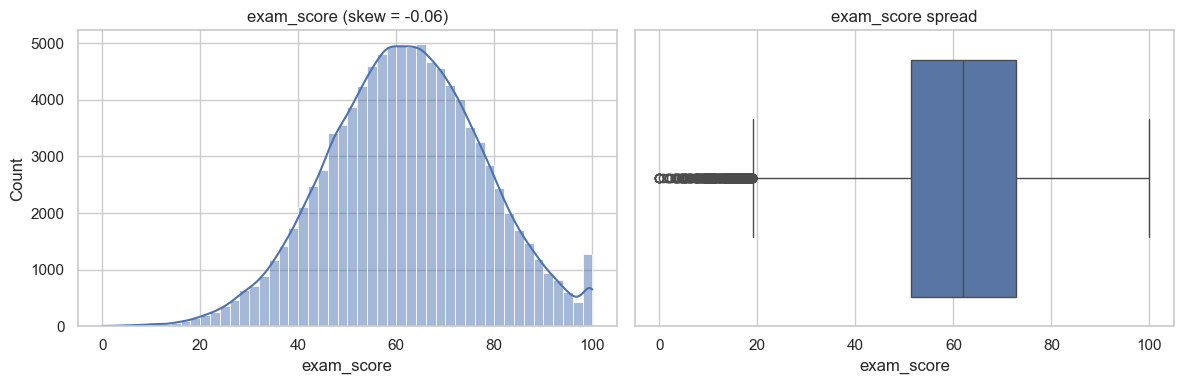

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=axes[0])
axes[0].set_title(f"exam_score (skew = {df[TARGET].skew():.2f})")
sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title("exam_score spread")
plt.tight_layout()
plt.show()

`exam_score` is normally distributed, so it does not require any transformation. The spread of the variable is around $60\%$, with some outlier between $0\%$ and $20\%$.

### Numerical values

We would like to visualise how the numerical values are distributed and is any of them are skewed.

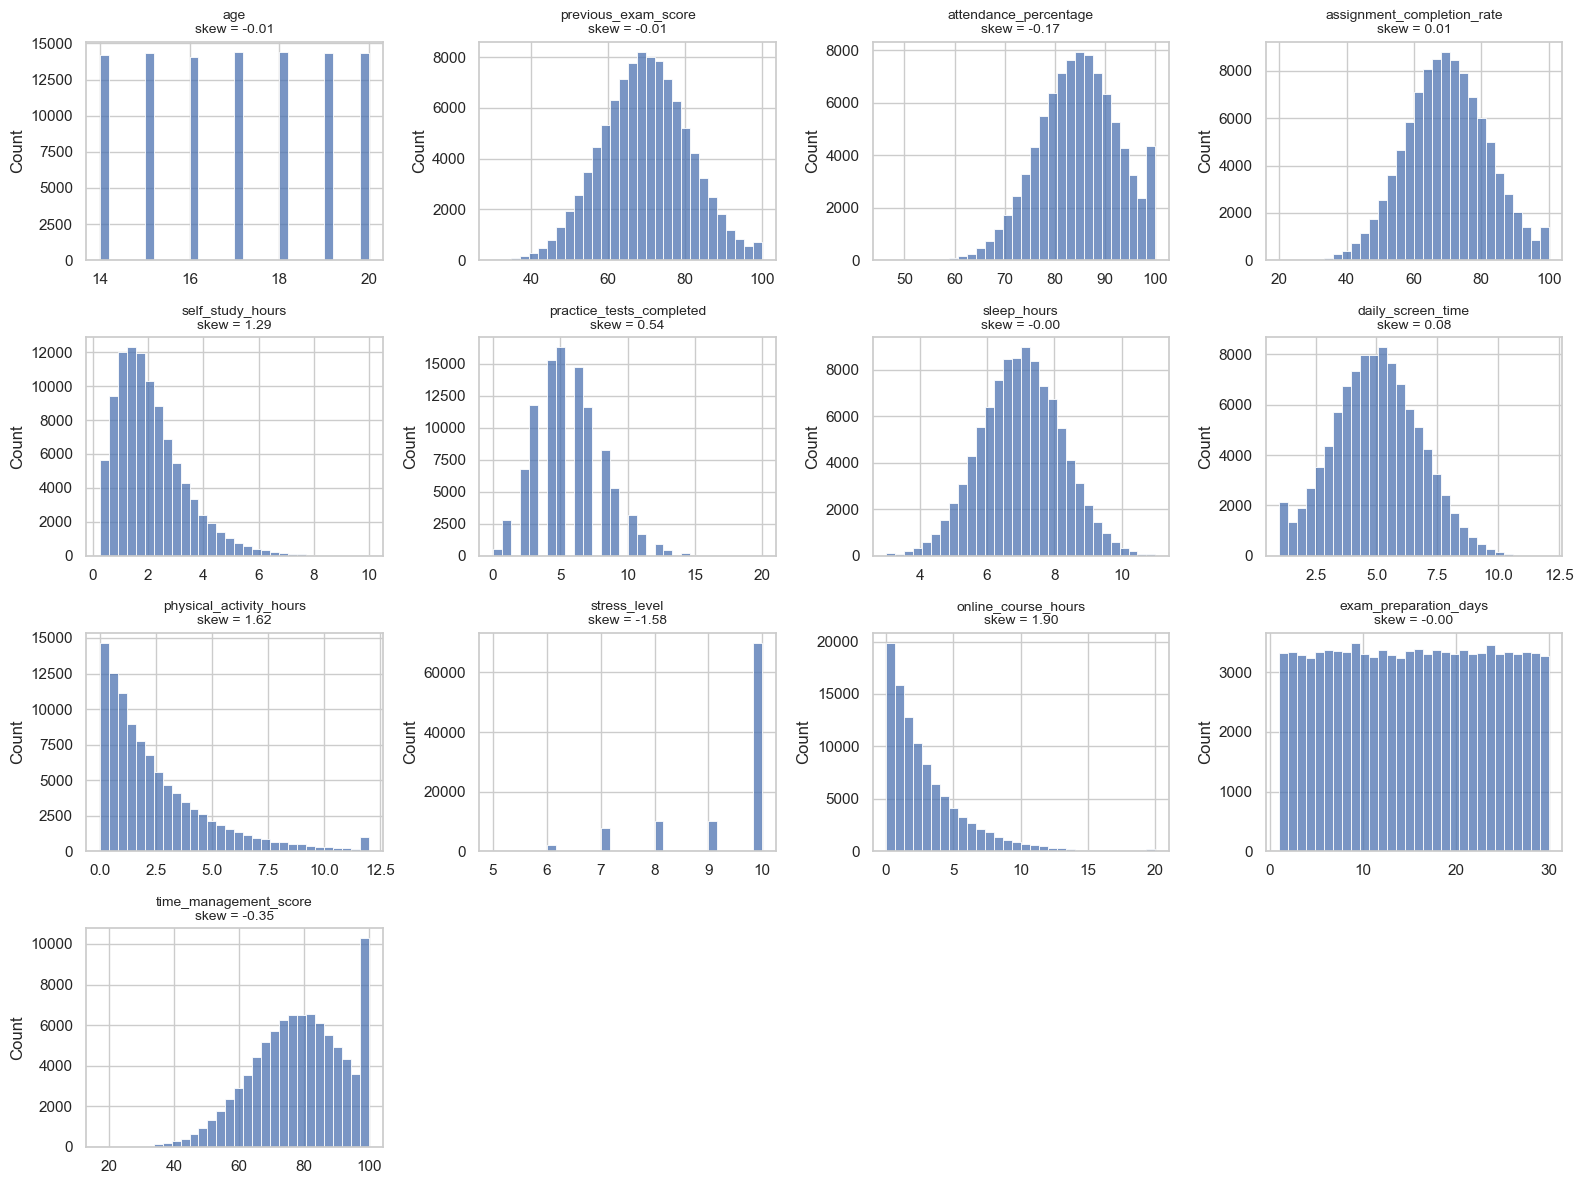

In [15]:
def hist_grid(cols, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        sns.histplot(df[c].dropna(), bins=30, ax=ax)
        ax.set_title(f"{c}\nskew = {df[c].skew():.2f}", fontsize=10)
        ax.set_xlabel("")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

hist_grid(num_cols)

In [16]:
skew = df[num_cols].skew().sort_values()
print("Most skewed numeric columns:")
display(skew[skew.abs() > 1].to_frame("skew"))

Most skewed numeric columns:


,skew
stress_level,-1.582138
self_study_hours,1.287089
physical_activity_hours,1.619581
online_course_hours,1.901414


We can see that `self_study_hours`, `physical_activity_hours`, `online_course_hours` and `stress_level` are all skewed and if we decide to use them as features, we might need to transform them.

### Binary and cathegorical values

Next, we take a lok at the binary and cathegotical features.

/var/folders/nc/59r_nr9j10df9yjwcyrl2x0m0000gn/T/ipykernel_34653/3917981318.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vc = df[c].astype("object").fillna("Missing").value_counts(normalize=True)


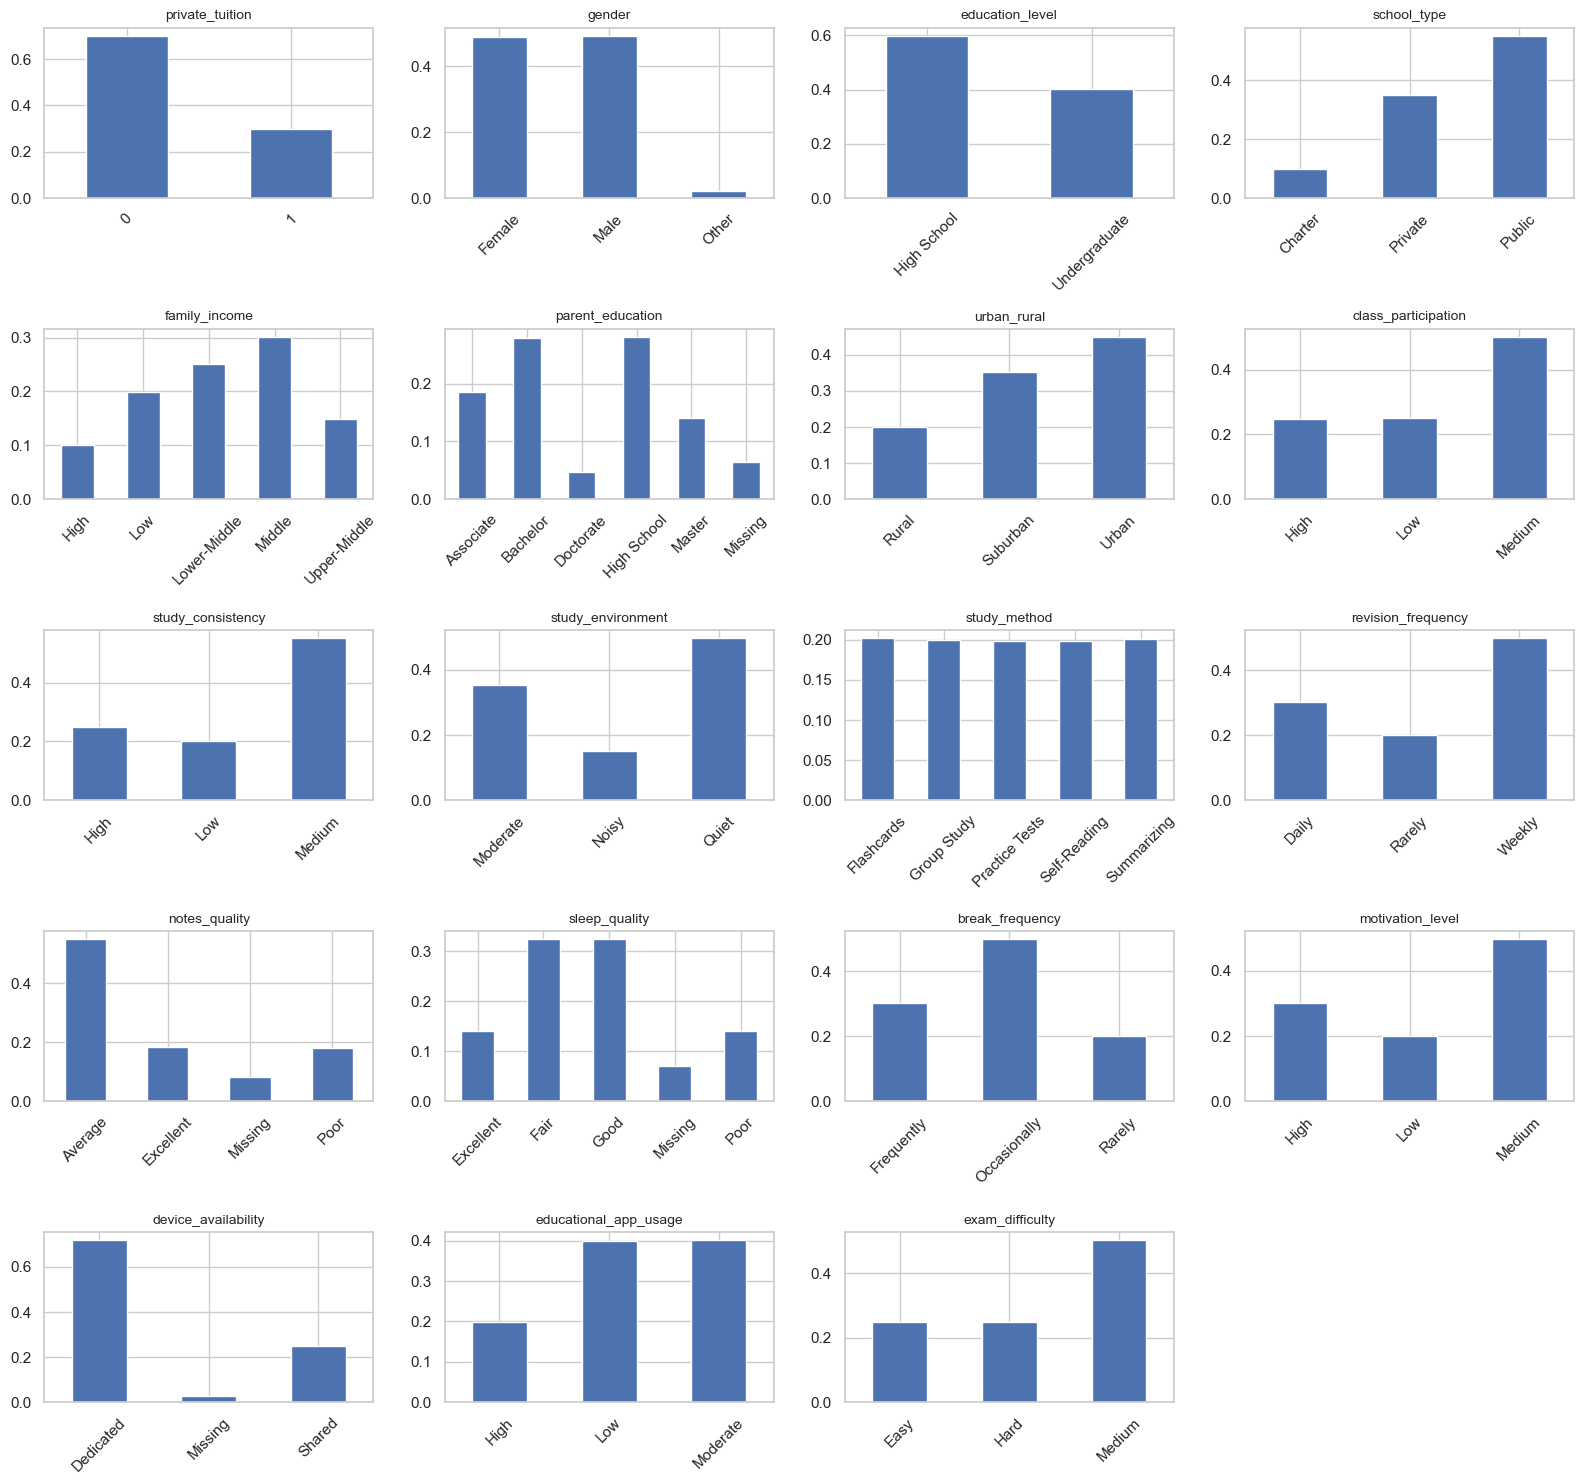

In [17]:
def bar_grid(cols, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        vc = df[c].astype("object").fillna("Missing").value_counts(normalize=True)
        vc.sort_index().plot.bar(ax=ax)
        ax.set_title(c, fontsize=10)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

bar_grid(binary_cols + cat_cols)

The binary and cathegorical variables seem quite even. None of them seem to have redundante cathegories that would need to be combined.

# Relationship between variables

Numeric and binary correlation (Pearson - linear rel., Spearman - monotonic rel.) between the variables.

,pearson,spearman
previous_exam_score,0.494,0.479
self_study_hours,0.343,0.324
practice_tests_completed,0.316,0.299
assignment_completion_rate,0.221,0.210
exam_preparation_days,0.199,0.191
sleep_hours,0.171,0.163
attendance_percentage,0.169,0.161
stress_level,-0.162,-0.147
time_management_score,0.107,0.104
daily_screen_time,0.005,0.004


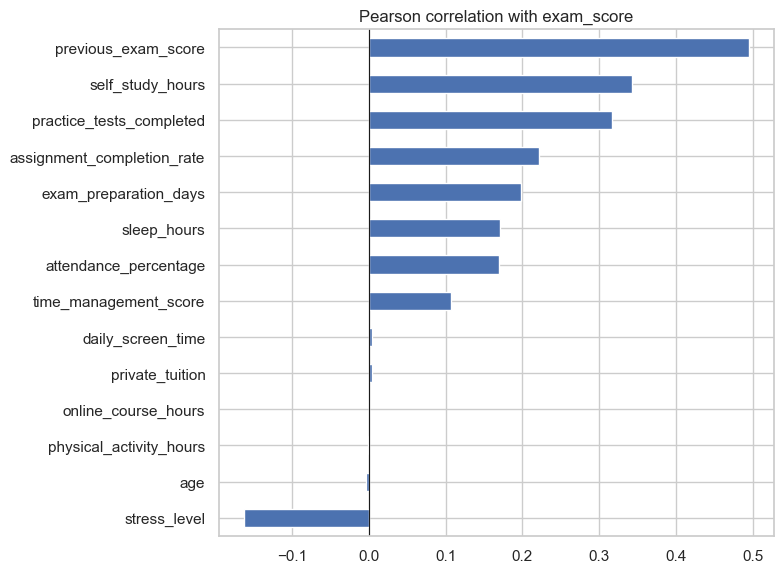

In [18]:
cols = num_cols + binary_cols
corr = pd.DataFrame({
    "pearson": df[cols].corrwith(df[TARGET]),
    "spearman": df[cols].corrwith(df[TARGET], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)

display(corr.round(3))

fig, ax = plt.subplots(figsize=(8, 0.35 * len(corr) + 1))
corr["pearson"].sort_values().plot.barh(ax=ax)
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Pearson correlation with exam_score")
plt.tight_layout()
plt.show()

We can se that `previous_exam_score`, `self_study_hours` and `practice_test_completed` show the highest correlation to `exam_score`. Interestingly, `stress_level` seems the most negatively correlated, so the higher the stress level of the individual the higher the likelihood of getting a lower test score.

What is the relationship between the most influential features and `exam_score`?

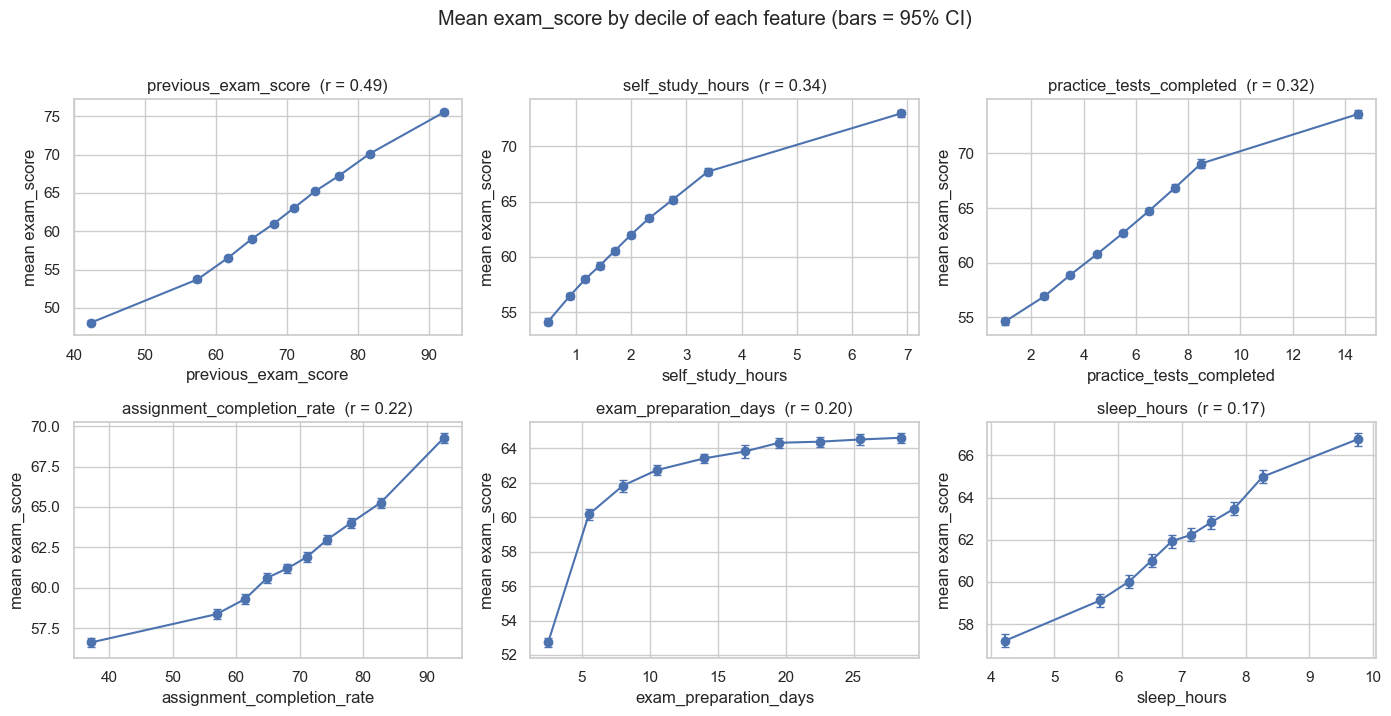

In [19]:
top = corr.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), top):
    if c in binary_cols:
        g = df.groupby(c)[TARGET].agg(["mean", "sem"])
        ax.errorbar(g.index, g["mean"], yerr=1.96 * g["sem"], fmt="o-", capsize=4)
        ax.set_xticks(g.index)
    else:
        bins = pd.qcut(df[c], 10, duplicates="drop")
        g = df.groupby(bins, observed=True)[TARGET].agg(["mean", "sem"])
        x = g.index.map(lambda i: i.mid).astype(float)
        ax.errorbar(x, g["mean"], yerr=1.96 * g["sem"], fmt="o-", capsize=3)
    ax.set_title(f"{c}  (r = {corr.loc[c, 'pearson']:.2f})")
    ax.set_xlabel(c)
    ax.set_ylabel("mean exam_score")
plt.suptitle("Mean exam_score by decile of each feature (bars = 95% CI)", y=1.02)
plt.tight_layout()
plt.show()

Most of the variables seem to have an almost linear relationship with `exam_score`, except for `exam_preparation_days`, which seem more like a logarithmic function and implies that the optimal amount of prep days would be between $6$ to $14$, because after that there is not much improvement.

Another measure is eta squared, which determines how much of the variation is explained by its cathegory.

,eta_squared
exam_difficulty,0.1114
family_income,0.0148
break_frequency,0.0001
parent_education,0.0001
school_type,0.0001
notes_quality,0.0001
study_method,0.0000
sleep_quality,0.0000
class_participation,0.0000
urban_rural,0.0000


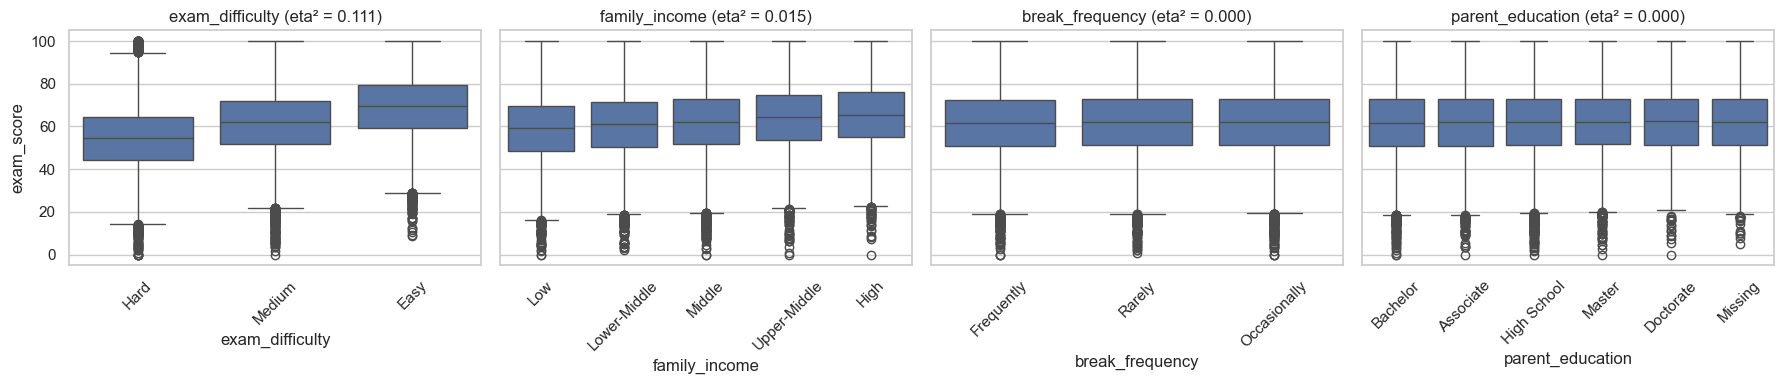

In [20]:
def eta_squared(groups, y):
    d = pd.DataFrame({"g": groups.astype("object").fillna("Missing"), "y": y})
    grand = d["y"].mean()
    ss_between = d.groupby("g")["y"].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    return ss_between / ((d["y"] - grand) ** 2).sum()

eta = pd.Series({c: eta_squared(df[c], df[TARGET]) for c in cat_cols}).sort_values(ascending=False)
display(eta.round(4).to_frame("eta_squared"))

top_cat = eta.index[:4]
fig, axes = plt.subplots(1, len(top_cat), figsize=(4.5 * len(top_cat), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, top_cat):
    tmp = df[[c, TARGET]].copy()
    tmp[c] = tmp[c].astype("object").fillna("Missing")
    order = tmp.groupby(c)[TARGET].mean().sort_values().index
    sns.boxplot(data=tmp, x=c, y=TARGET, order=order, ax=ax)
    ax.set_title(f"{c} (eta² = {eta[c]:.3f})")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Most of them it is not, except for `exam_difficulty`, which has a value of $0.111$.

## Data Splitting

### Handling missing variables
Six columns have missing values. Linear regression and Lasso cannot be fitted with empty entries, so we keep only the rows that are compatible in all 32 candidate variables. We chose this because it is the simples option that does not invent new values. Filling the gaps with the mean would give more rows but also make the data look more certain than it is. 

### Train/test split
The complete rows are split randomly into training set (80%) and a test set (20%) with a fixed random seed. The test seet is only used to report the final accuracy, to get an honest estimate of how the model would do on new students. 

In [21]:
assert not set(REDUNDANT_COLS) & set(features), "REDUNDANT_COLS still in features"
#keeping only rows with no missing value in the chosen columns (could improve this?)

data = df.dropna(subset=features)
print(f"{len(data)} of {len(df)} rows kept")

62897 of 100000 rows kept


In [22]:
# train/test split 80/20

X = data[features]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(50317, 32) (12580, 32)


## Preprocessing

The variables are put in a form the models can use: 
- **Numeric and binary variables are standardised** (mean 0, standard deviation1). Each coefficient is then the change in `exam_score` for an increase of one standard deviation in the variable, so that the coefficients can be compared. This also matters for Lasso since the penalty would otherwise depend on the units of each variable.
- **Categorical variables are one-hot encoded**: Each category becomes its own 0/1 column. One category per variable is left out as the reference, otherwise the columns would be perfectly collinear.

The 32 variables become 55 columns. Everything is wrapped in a `scikit-learn` pipeline, standard deviations and categories are learned from the training data only and then applied to the new data. 

In [23]:
# some preprocessing

def build_pre(cols):
    num = [c for c in num_cols + binary_cols if c in cols]
    cat = [c for c in cat_cols if c in cols]
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),cat),
    ])

def make_pipe(model, cols=None):
    cols = features if cols is None else cols
    return Pipeline([("pre", build_pre(cols)), ("model", model)])

#prepared training data
pre = build_pre(features)
Z = pd.DataFrame(pre.fit_transform(X_train), columns=pre.get_feature_names_out(), index=X_train.index)
print(Z.shape)

(50317, 55)


## Linear Model

### Why linear regression 

We want to understand both whoch variables matter and predict the `exam_score`. Linear regression, using least squares, makes it possible to do these two things. Each coefficient is the change in the predicted score for a one standard deviationchange in a variable, holding the others fixed, and with a confidence interval. 

Limitations: it assumes straight-line effects, no interaction between variables, constant error variance and normal residuals. It cannot respect $0-100$ bounds of the score. 

,coef,ci_low,ci_high,p_value
cat__exam_difficulty_Hard,-15.091,-15.331,-14.852,0.000
num__previous_exam_score,7.721,7.635,7.807,0.000
cat__exam_difficulty_Medium,-7.528,-7.734,-7.321,0.000
num__self_study_hours,4.089,3.992,4.187,0.000
num__practice_tests_completed,3.577,3.488,3.666,0.000
num__exam_preparation_days,3.062,2.978,3.146,0.000
num__attendance_percentage,2.275,2.181,2.370,0.000
num__stress_level,-2.146,-2.232,-2.060,0.000
num__sleep_hours,2.033,1.946,2.120,0.000
num__time_management_score,1.295,1.210,1.380,0.000


R^2 on training data = 0.632


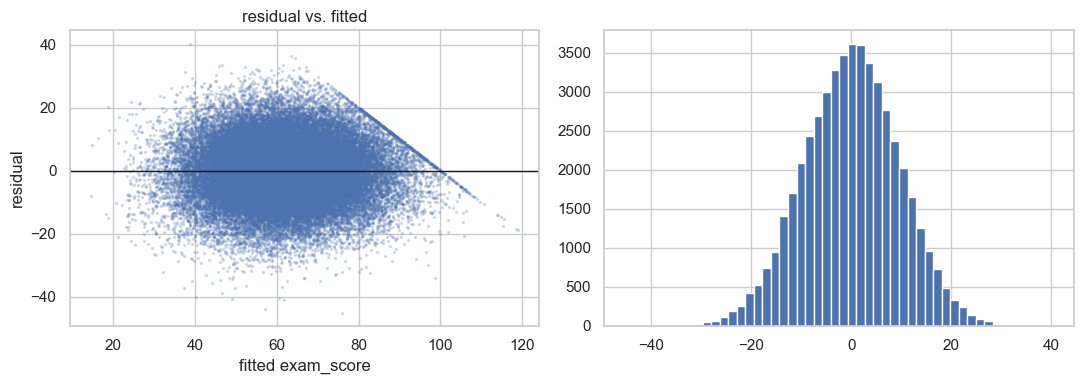

In [24]:
# linear regression

A = np.column_stack([np.ones(len(Z)), Z.values])
names = ["const"] + list(Z.columns)
beta, *_ = np.linalg.lstsq(A, y_train.values, rcond=None)
fitted = A @ beta
resid = y_train.values - fitted

dof = len(y_train) - A.shape[1] #degs of freedom
sigma2 = resid @ resid /dof
se = np.sqrt(np.diag(np.linalg.inv(A.T @ A)) * sigma2)
p = 2* stats.t.sf(np.abs(beta/se), dof)
tcrit = stats.t.ppf(0.975, dof)

ols_tab = pd.DataFrame({"coef": beta, "ci_low": beta-tcrit*se,
                        "ci_high": beta+tcrit*se, "p_value":p}, index=names).drop("const")
r2_train = 1- resid@resid/ ((y_train.values - y_train.mean())**2). sum()

display(ols_tab.reindex(ols_tab["coef"].abs().sort_values(ascending=False).index).round(3).head(25))
print(f"R^2 on training data = {r2_train:.3f}")

fig,ax = plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(fitted, resid, s=2, alpha=0.2)
ax[0].axhline(0, color='k', lw=1)
ax[0].set(xlabel="fitted exam_score", ylabel="residual", title="residual vs. fitted")
ax[1].hist(resid, bins=50)
plt.tight_layout()
plt.show()



### Results

The model explains $63.2\%$ of the variance in the training data. The largest effects are `exam_difficulty`, `previous_exam_score`, `self_study_hours`,`practice_tests_completed`, `exam_preparation_days`, `stress_level` and `sleep_hours`. Every other coefficient is smaller than about $0.25$ and most of their confidence intervals include zero.

### Checking assumptions
The residual vs fitted plot is a scatter plot because the assumption concern patterns and a scatter shows any curve or shape. The cloud is centred around zero with no curve and a roughly event spread, so the linear form is reasonable. The straight line in the upper right corner could be caused by the cap at $100$. 

The hisotgram if the residuals shows the shape of the errors directly. It is symmetric and bell-shaped so the confidence intervals can be trusted. 

test R^2 = 0.636
test rmse = 9.62 points


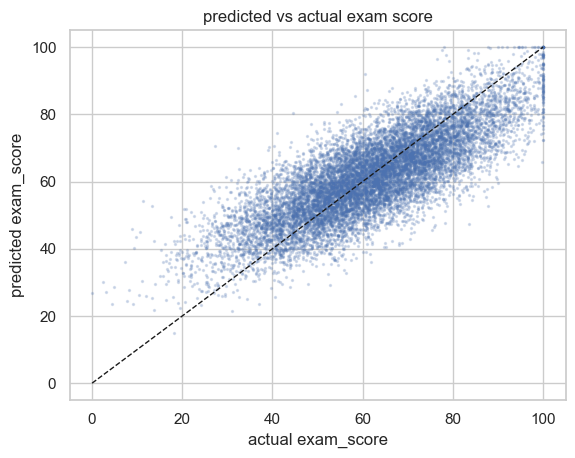

In [25]:
#prediction 

lin = make_pipe(LinearRegression())
lin.fit(X_train, y_train)

pred = lin.predict(X_test)
pred_clipped = np.clip(pred,0,100) #exam score is between 0 and 100
print(f"test R^2 = {r2_score(y_test, pred):.3f}")
print(f"test rmse = {mean_squared_error(y_test, pred)**0.5:.2f} points")

#predicted vs. actual 
plt.scatter(y_test, pred_clipped, s=2, alpha=0.2)
plt.plot([0,100],[0,100], "k--", lw=1)
plt.xlabel("actual exam_score")
plt.ylabel("predicted exam_score")
plt.title("predicted vs actual exam score")
plt.show()

### Prediction on the test set

On the students that were not used for fitting, the model gets $R^2 = 0.636$ and RMSE = 9.62 points. The training $R^2$ (0.632) and the test $R^2$ are almost identical, so the model is not overfitted. 

The predicted vs actual plot shows accuracy directly. A perfect model would put every output on the dashed line. The poitns follow the line but the cloud is wide.

### Lasso Regression

Linear regression keeps all $32$ variables, but many probably add very little. Lasso adds penalty on the sum of the absolute sizes of the ciefficients, which shrinks weak coefficients to zero. The penalty strength $\alpha$ decides how many variables are removed. This fits out aim of finding what matters and what does not imoact the exam_score. 

Its limitations: The penalty biases the coefficients toward zero, so we use Lasso only to choose variables and then refit the ordinary linear regression. When variables are related Lasso tends to keep one of them and the choice is arbitrary. 

alpha (lowest CV error)= 0.0239, alpha (one-SE rule)=0.1189


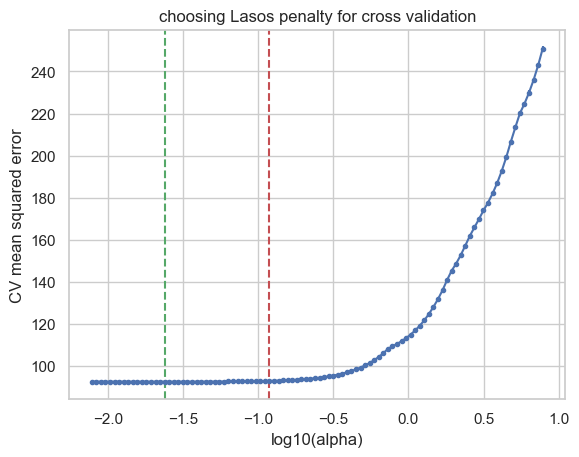

11 of 55 coefs are non-zero


cat__exam_difficulty_Hard         -13.646
num__previous_exam_score            7.613
cat__exam_difficulty_Medium        -6.322
num__self_study_hours               4.010
num__practice_tests_completed       3.491
num__exam_preparation_days          2.942
num__attendance_percentage          2.173
num__stress_level                  -2.047
num__sleep_hours                    1.950
num__time_management_score          1.187
num__assignment_completion_rate     0.300
dtype: float64

In [38]:
# lasso 

lasso_cv = LassoCV(cv=5, random_state=42, n_jobs=-1)
lasso_cv.fit(Z, y_train)

mse = lasso_cv.mse_path_.mean(axis=1)
se = lasso_cv.mse_path_.std(axis=1)/ np.sqrt(lasso_cv.mse_path_.shape[1])
i_min = mse.argmin()
alpha_min = lasso_cv.alphas_[i_min]
alpha_1se = lasso_cv.alphas_[mse <= mse[i_min] + se[i_min]].max()
print(f"alpha (lowest CV error)= {alpha_min:.4f}, alpha (one-SE rule)={alpha_1se:.4f}")

plt.errorbar(np.log10(lasso_cv.alphas_), mse, yerr=se, fmt="o-", ms=3)
plt.axvline(np.log10(alpha_min), ls="--", c="g", label="lowest CV error")
plt.axvline(np.log10(alpha_1se), ls="--", c="r", label="one-SE rule")
plt.xlabel("log10(alpha)")
plt.ylabel("CV mean squared error")
plt.title("choosing Lasos penalty for cross validation")
plt.show()

# gives the most imporant variables

lasso = Lasso(alpha=alpha_1se).fit(Z, y_train)
lasso_coef = pd.Series(lasso.coef_, index=Z.columns)
print(f"{(lasso_coef != 0).sum()} of {len(lasso_coef)} coefs are non-zero")
display(lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False).round(3))

### Choosing the penalty
$\alpha$ is chosen by $5$-fold cross-validation on the training set: for each $\alpha$ the model is fitted on $\frac{4}{5}$ of the data and its error is measured on the remining $\frac{1}{5}$, five times. The lines plot shows the average error against $\log_{10}(\alpha)$. The bars show the standard error. A line plot suits a continuous setting where we want to see where the error starts to rise. 

The curve is flat for small penalties, so many variables can be removed for free. It rises once the penalty is so strong that important coefficients are shrunk. The green line marks the lowest error ($\alpha = 0.0239$), the red line marks the largest $\alpha$ whose error is within one standard error of the minimum (to follow the one-standard-error rule). 

### Cross validation 

In [39]:
models = { "Linear Regression": make_pipe(LinearRegression()),
           "Lasso": make_pipe(LassoCV(cv=5, random_state=42)),}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows=[]
for name, model in models.items():
    r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")
    rmse = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    rows.append({"model": name, "CV R^2 mean": r2.mean(), "CV R^2 sd": r2.std(), "CV RMSE mean": rmse.mean()})
display(pd.DataFrame(rows).set_index("model").round(3))

,CV R^2 mean,CV R^2 sd,CV RMSE mean
model,,,
Linear Regression,0.631,0.005,9.624
Lasso,0.631,0.005,9.620


We compare linear regression and Lasso with $5$-fold cross-validation on the training set. Each model is trained on $\frac{4}{5}$ of the data and scored on the rest, five times. We see $R^2$ and RMSE. For Lasso $\alpha$ is chosen again by cross-validation inside each fold. 

Both models get $R^2 = 0.631 \pm 0.005$ and RMSE of $9.62$. The difference of $0.004$ RMSE points is much smaller than the variation between folds, so the models predict equally well. This is expected: with about $50,000$ training rows and only $55$ columns, linear regression does not overfit so the penalty has little to fix. 

In [40]:
def original_column(feature_name):
    if feature_name.startswith("num__"):
        return feature_name[len("num__"):]
    name = feature_name[len("cat__"):]
    return next(c for c in cat_cols if name.startswith(c + "_"))

kept = sorted({original_column(n) for n in lasso_coef[lasso_coef != 0].index})
dropped = [c for c in features if c not in kept]
print(f"Lasso keeps {len(kept)} of {len(features)} variables.")
print("Dropped:", dropped)

# fit linear regression on the kept variables only 
reduced = make_pipe(LinearRegression(), kept)
r2 = cross_val_score(reduced, X_train, y_train, cv=cv, scoring="r2")
reduced.fit(X_train, y_train)
pred = reduced.predict(X_test)
print(f"Reduced linear regression: CV R² = {r2.mean():.3f}, test R² = {r2_score(y_test, pred):.3f}, "
      f"test RMSE = {mean_squared_error(y_test, pred) ** 0.5:.2f}")

Lasso keeps 10 of 32 variables.
Dropped: ['age', 'gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'class_participation', 'private_tuition', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'daily_screen_time', 'physical_activity_hours', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'online_course_hours']
Reduced linear regression: CV R² = 0.631, test R² = 0.637, test RMSE = 9.62


### The reduced model

Lasso keeps $10$ of the $32$ variables. Refitting ordinary linear regression on only these $10$ variables gives cross-validated $R^2 = 0.631$, test $R^2=0.637$ and RMSE $=9.62$ points, which is the same as the old model. 

### Final coefficients
The plot shows each coefficient with its $95\%$ confidence interval on one common scale, with a line at zero to show which effects differ from zero. 

- **Exam difficulty:** Hard $-15.1$ and Medium $-7.5$ points, compared with Easy.
- **Previous exam score:** $+0.68$ points per point.
- **Self-study hours:** $+3.2$ points per extra hour.
- **Practice tests:** $+1.4$ points per extra test.
- **Preparation days:** $+0.35$ points per day.
- **Attendance:** $+0.29$ points per percentage point.
- **Stress level:** $-2.0$ points per step.
- **Sleep:** $+1.7$ points per hour.
- **Time management and assignment completion:** about $+0.09$ and $+0.03$ points per unit, which is very small.

Each effect holds the other nine variables fixed and describes an association, not a cause.

## Doing the prediction with only contributing variables found in Lasso


,coef,ci_low,ci_high,p_value
cat__exam_difficulty_Hard,-15.093,-15.332,-14.854,0.0
num__previous_exam_score,7.725,7.641,7.809,0.0
cat__exam_difficulty_Medium,-7.530,-7.737,-7.323,0.0
num__self_study_hours,4.088,3.990,4.185,0.0
num__practice_tests_completed,3.579,3.491,3.668,0.0
num__exam_preparation_days,3.061,2.977,3.145,0.0
num__attendance_percentage,2.280,2.187,2.373,0.0
num__stress_level,-2.145,-2.231,-2.060,0.0
num__sleep_hours,2.032,1.945,2.119,0.0
num__time_management_score,1.294,1.209,1.379,0.0


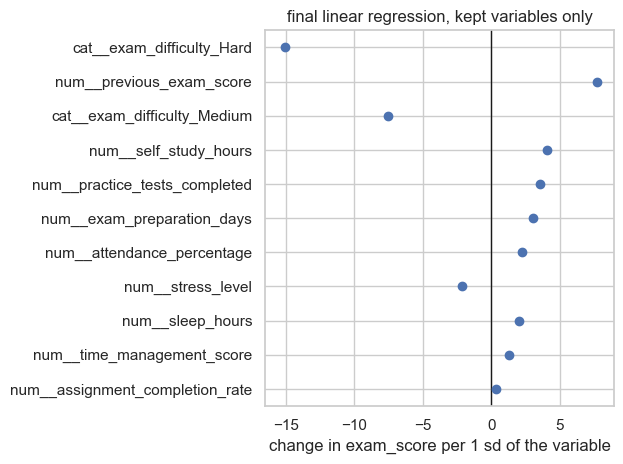

In [34]:
# prepare training with only the kept variables
from scipy import stats
pre_k = build_pre(kept)
Zk = pd.DataFrame(pre_k.fit_transform(X_train), columns=pre_k.get_feature_names_out(), index=X_train.index)

#linear regression on kept variables, with confidence interval and p values
A = np.column_stack([np.ones(len(Zk)), Zk.values])
names = ["const"]+list(Zk.columns)
beta, *_ = np.linalg.lstsq(A,y_train.values, rcond=None)
resid = y_train.values - A@beta
dof = len(y_train) -A.shape[1]
sigma2 = resid@resid /dof
se = np.sqrt(np.diag(np.linalg.inv(A.T@A))*sigma2)
p = 2* stats.t.sf(np.abs(beta/se), dof)
tcrit = stats.t.ppf(0.975, dof)

final_tab = pd.DataFrame({"coef": beta, "ci_low":beta-tcrit*se, "ci_high":beta+tcrit*se, "p_value":p}, index=names).drop("const")
final_tab = final_tab.reindex(final_tab["coef"].abs().sort_values(ascending=False).index)
display(final_tab.round(3))

#coef with 95% confidence interval
ft = final_tab.iloc[::-1]
plt.errorbar(ft["coef"], range(len(ft)), xerr=[ft["coef"]-ft["ci_low"], ft["ci_high"]-ft["coef"]],fmt="o")
plt.yticks(range(len(ft)), ft.index)
plt.axvline(0, color="k", lw=1)
plt.xlabel("change in exam_score per 1 sd of the variable")
plt.title("final linear regression, kept variables only")
plt.tight_layout()
plt.show()


Average difference between the two models' predictions: 0.22 points
95% of students differ by less than 0.53 points (the models' typical error is 9.6 points)


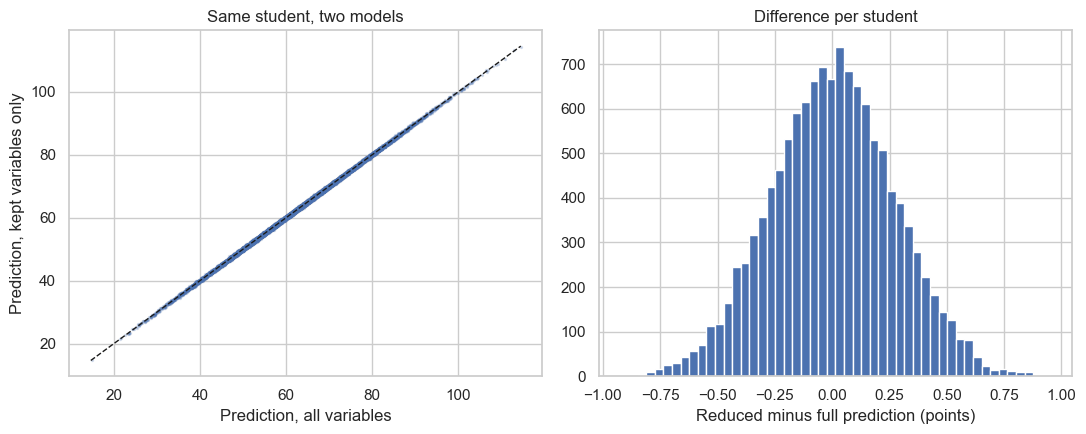

,n variables,CV R²,sd
0,1,0.113,0.006
1,2,0.356,0.004
2,3,0.473,0.005
3,4,0.518,0.005
4,5,0.556,0.004
5,6,0.579,0.005
6,8,0.624,0.005
7,10,0.631,0.005
8,12,0.631,0.005
9,15,0.631,0.005


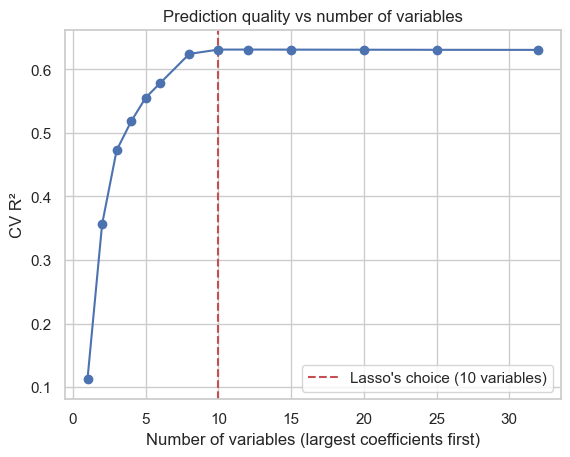

In [36]:
# Plot 1: do the two models predict the same exam scores for the same students?
full = make_pipe(LinearRegression()).fit(X_train, y_train)
red = make_pipe(LinearRegression(), kept).fit(X_train, y_train)
p_full, p_red = full.predict(X_test), red.predict(X_test)
diff = p_red - p_full

print(f"Average difference between the two models' predictions: {np.abs(diff).mean():.2f} points")
print(f"95% of students differ by less than {np.percentile(np.abs(diff), 95):.2f} points "
      f"(the models' typical error is {mean_squared_error(y_test, p_full) ** 0.5:.1f} points)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
lo, hi = min(p_full.min(), p_red.min()), max(p_full.max(), p_red.max())
ax[0].scatter(p_full, p_red, s=2, alpha=0.2)
ax[0].plot([lo, hi], [lo, hi], "k--", lw=1)
ax[0].set(xlabel="Prediction, all variables", ylabel="Prediction, kept variables only",
          title="Same student, two models")
ax[1].hist(diff, bins=50)
ax[1].set(xlabel="Reduced minus full prediction (points)", title="Difference per student")
plt.tight_layout()
plt.show()

# Plot 2: how does prediction quality change as variables are added?
rank = ols_tab["coef"].abs().groupby(ols_tab.index.map(original_column)).max().sort_values(ascending=False)
ks = sorted({k for k in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, len(rank)] if k <= len(rank)})
scores = []
for k in ks:
    cols = list(rank.index[:k])
    r2 = cross_val_score(make_pipe(LinearRegression(), cols), X_train, y_train, cv=cv, scoring="r2")
    scores.append((k, r2.mean(), r2.std()))
sc = pd.DataFrame(scores, columns=["n variables", "CV R²", "sd"])
display(sc.round(3))

plt.errorbar(sc["n variables"], sc["CV R²"], yerr=sc["sd"], marker="o")
plt.axvline(len(kept), ls="--", c="r", label=f"Lasso's choice ({len(kept)} variables)")
plt.xlabel("Number of variables (largest coefficients first)")
plt.ylabel("CV R²")
plt.title("Prediction quality vs number of variables")
plt.legend()
plt.show()

,n variables,CV RMSE,sd
0,1,14.91,0.10
1,2,12.71,0.08
2,3,11.50,0.04
3,4,10.99,0.03
4,5,10.56,0.03
5,6,10.28,0.02
6,8,9.71,0.01
7,10,9.62,0.01
8,12,9.62,0.01
9,15,9.62,0.02


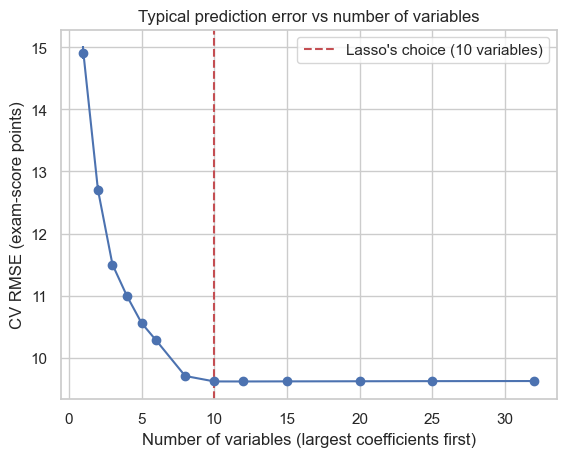

In [37]:
rmse_rows = []
for k in ks:
    cols = list(rank.index[:k])
    e = -cross_val_score(make_pipe(LinearRegression(), cols), X_train, y_train,
                         cv=cv, scoring="neg_root_mean_squared_error")
    rmse_rows.append((k, e.mean(), e.std()))
sc_rmse = pd.DataFrame(rmse_rows, columns=["n variables", "CV RMSE", "sd"])
display(sc_rmse.round(2))

plt.errorbar(sc_rmse["n variables"], sc_rmse["CV RMSE"], yerr=sc_rmse["sd"], marker="o")
plt.axvline(len(kept), ls="--", c="r", label=f"Lasso's choice ({len(kept)} variables)")
plt.xlabel("Number of variables (largest coefficients first)")
plt.ylabel("CV RMSE (exam-score points)")
plt.title("Typical prediction error vs number of variables")
plt.legend()
plt.show()

### Does removing 22 variables change the predictions?

The scatter plot compares, for each test student, the prediction of the full model with the prediction of the reduced model. Points on the diagonal mean the models agree. The histogram shows the size of the differences. 

The next plot shows the cross-validated $R^2$ as variables are added, where the number of variables is ordered in the line-plot. $R^2$ rises steeply and reaches $0.631$ at $10$, then stays flat up to all $32$. 

The last plot shows the same thing as RMSE in exam-score points: it falls from $14.9$ points with one variable to $9.62$ with $10$ does not improve after that. 

## Conclusions

- **Prediction:** with $10$ variables, linear regression explains $63\%$ of the variance in `exam_score` for unseen students, with a typical error of $9.6$ points.
- **What matters:** exam difficulty and previous exam score are by far the largest effects. Among the things a student can influence, self-study hours, practice tests, preparation days, attendance, sleep and stress matter most.
- **What does not:** background variables (gender, school type, family income, parent education) and most habits (study method, motivation, screen time) add nothing detectable to the prediction.
- **Simplicity:** $22$ of the $32$ variables could be removed with no loss in accuracy.
